# PoC · Asistente de apoyo al psicodiagnóstico (LC-B + LC-C)
**Kit PoC · Colab + LangChain + OpenRouter** · Entrada: texto o foto de una nota manuscrita

Flujo: (si es una foto, **OCR**) → el texto se **anonimiza** (NER local; nombres, lugares y organizaciones no salen de la VM) →
**guardrail** de contexto clínico (`typesafe/jev-1.14-20261014`) → **extraer** síntomas →
**agente CIE-11** (MCP en Azure) → **guías clínicas** (IMSS siempre; APA y/u OMS si JEV lo decide) → **reporte** Markdown con código y liga OMS.

1. Abre este cuaderno en Colab y monta Google Drive cuando lo pida (la carpeta `poc_psicodiagnostico` debe estar en tu Drive).
2. Guarda `OPENROUTER_API_KEY` en los Secretos de Colab (acceso del notebook activado) o, en local, en el archivo `.env`.
3. Ejecuta todo. El modelo predeterminado (`anthropic/claude-haiku-5.5`) es de pago: la cuenta de OpenRouter necesita créditos (ver README).

> Trabaja solo con datos sintéticos o anonimizados: OpenRouter y, con Mistral OCR, Mistral reciben tus datos y pueden registrar el uso.


## 0 · Instalación, Drive y clave (no editar)

In [1]:
# 0.1 · Dependencias (no editar). En Colab se instalan aquí; en local vienen de uv sync (ver README)
import subprocess
import sys

if "google.colab" in sys.modules:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-qU",
        "langchain>=1.4,<2", "langchain-openai>=1.6,<2", "langgraph>=1.2,<2",
        "langchain-mcp-adapters", "transformers", "torch", "pydantic", "requests", "pandas", "python-dotenv", "pillow",
    ])
else:
    print("Entorno local: las dependencias vienen de uv sync (ver README).")

Entorno local: las dependencias vienen de uv sync (ver README).


In [2]:
# 0.2 · Drive y ruta del paquete poc_psico (no editar)
import os
import sys

RUTA_PROYECTO = "/content/drive/MyDrive/LLM solutions architect/Módulo 5/poc_psicodiagnostico"
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    RUTA_PROYECTO = os.getcwd()
sys.path.insert(0, RUTA_PROYECTO)
from poc_psico import grafo  # falla aquí si la ruta no es correcta
print("Paquete cargado desde", RUTA_PROYECTO)

Paquete cargado desde /Users/dalia/Library/CloudStorage/GoogleDrive-daliaf172@gmail.com/Mi unidad/LLM solutions architect/Módulo 5/poc_psicodiagnostico


In [3]:
# 0.3 · Clave de OpenRouter (no editar). Colab: Secretos. Local: archivo .env (ver README)
import getpass
from poc_psico.entorno import cargar_env

if cargar_env(os.path.join(RUTA_PROYECTO, ".env")):
    print("Variables cargadas desde .env")

def leer_secreto(nombre: str, obligatorio: bool = True):
    try:
        from google.colab import userdata
        valor = userdata.get(nombre)
        if valor:
            return valor
    except Exception:
        pass
    if os.environ.get(nombre):
        return os.environ[nombre]
    if obligatorio:
        return getpass.getpass(f"Pega tu {nombre}: ")
    return None

os.environ["OPENROUTER_API_KEY"] = leer_secreto("OPENROUTER_API_KEY")
langsmith_key = leer_secreto("LANGSMITH_API_KEY", obligatorio=False)
if langsmith_key:
    os.environ["LANGSMITH_API_KEY"] = langsmith_key
    os.environ["LANGSMITH_TRACING"] = "true"
    os.environ["LANGSMITH_PROJECT"] = "kit-poc"
print("Clave cargada. LangSmith:", "activo" if langsmith_key else "desactivado")

Variables cargadas desde .env
Clave cargada. LangSmith: desactivado


## 1 · Modelo y NER (no editar)

In [4]:
# 1.1 · Modelo: OpenRouter + Claude Haiku 5.5 (la alternativa gratuita, Nemotron, queda comentada; no editar)
from langchain_openai import ChatOpenAI
from langchain_core.globals import set_llm_cache
from langchain_core.caches import InMemoryCache

TEMPLATE_ID = "LC-B+C"
# MODEL_ID = "nvidia/nemotron-3-ultra-550b-a55b:free"
MODEL_ID = "anthropic/claude-haiku-5.5"
set_llm_cache(InMemoryCache())

llm = ChatOpenAI(
    model=MODEL_ID,
    api_key=os.environ["OPENROUTER_API_KEY"],
    base_url="https://openrouter.ai/api/v1",
    temperature=0,
    max_tokens=4096,
    timeout=120,
    max_retries=3,
    default_headers={"HTTP-Referer": "https://colab.research.google.com", "X-Title": "Kit PoC BSG"},
)

def texto(mensaje) -> str:
    return mensaje.text if hasattr(mensaje, "text") else str(mensaje.content)

print("Prueba de conexión:", texto(llm.invoke("Responde solo con la palabra OK.")))

Prueba de conexión: OK


In [5]:
# 1.2 · Modelo NER en español (corre en la VM de Colab; no usa API externa)
from transformers import pipeline

ner_es = pipeline("ner", model="MMG/xlm-roberta-large-ner-spanish", aggregation_strategy="simple")
print(ner_es("Mi nombre es Dalia Camacho y vivo en CDMX"))

/Users/dalia/.venvs/poc_psico/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 391/391 [00:00<00:00, 5763.88it/s]


[{'entity_group': 'PER', 'score': np.float32(0.9827172), 'word': 'Dalia Camacho', 'start': 13, 'end': 26}, {'entity_group': 'LOC', 'score': np.float32(0.90801215), 'word': 'CDMX', 'start': 37, 'end': 41}]


## 2 · Tu caso (EDITA AQUÍ)

In [6]:
# EDITA AQUÍ · 2.1 Guardrail, MCP y agente
UMBRAL_GUARDRAIL = 0.5          # probabilidad mínima de "contexto de psicología clínica"
AGENT_MCP_URL = os.getenv(
    "AGENT_MCP_URL",
    "https://cie11-mcp-server.orangerock-5a17ced7.eastus.azurecontainerapps.io/sse",
)
from poc_psico.agente import TOOLS_BASE, TOOLS_CON_SINTOMAS, PROMPT_AGENTE
TOOLS_PERMITIDAS = TOOLS_BASE   # prueba también TOOLS_CON_SINTOMAS y compara las rondas
SYSTEM_PROMPT_AGENTE = PROMPT_AGENTE
MAX_RONDAS = 5                 # rondas de tools que puede dar el agente (el agente ve cuántas lleva)
# Guías clínicas: siempre IMSS; JEV decide si añade APA y/u OMS (plugin web de OpenRouter, una búsqueda por dominio; solo viajan los títulos CIE-11, nunca datos del paciente).
# Cuesta de 1 a 3 búsquedas por caso (unos US$0.008 cada una) más una llamada de decisión; si falla, el reporte sale sin guías y con una advertencia.
BUSCAR_GUIAS = True

In [7]:
# EDITA AQUÍ · 2.2 Contrato de síntomas y de reporte
# Los contratos Pydantic y los prompts del extractor y del redactor están en
# poc_psico/esquemas.py y poc_psico/nodos.py; edítalos ahí y reinicia el entorno.
from poc_psico.esquemas import SintomasPaciente, ReporteClinico
print("Síntomas:", list(SintomasPaciente.model_fields))
print("Reporte:", list(ReporteClinico.model_fields))

Síntomas: ['paciente_ref', 'edad', 'sexo', 'cognitivos', 'emocionales', 'conductuales', 'afectacion_social', 'temporalidad', 'datos_faltantes']
Reporte: ['hipotesis', 'ambiguedades', 'diferenciales', 'datos_faltantes', 'pruebas']


In [8]:
# EDITA AQUÍ · 2.3 Casos de prueba (sintéticos)
from poc_psico.casos import CASOS
print(f"{len(CASOS)} casos:", [c["id"] for c in CASOS])

4 casos: ['P1', 'P2', 'P3', 'P4']


## 3 · Construcción del flujo (no editar)

In [9]:
# 3.1 · Componentes y grafo (no editar)
from poc_psico.agente import cargar_tools, construir_agente, correr_agente
from poc_psico.grafo import Componentes, construir_workflow, ejecutar
from poc_psico.guardrail import consultar_decisions
from poc_psico.guias import buscar_guias, crear_decisor_fuentes, crear_decisor_jev
from poc_psico.nodos import crear_extractor, crear_redactor
from poc_psico.ocr import leer_imagen_mistral

tools = await cargar_tools(AGENT_MCP_URL, TOOLS_PERMITIDAS)
agente = construir_agente(llm, tools, SYSTEM_PROMPT_AGENTE, MAX_RONDAS)

async def _agente(sintomas):
    return await correr_agente(agente, sintomas, MAX_RONDAS)

def _ocr(ruta):  # Mistral OCR vía OpenRouter: la foto sale a OpenRouter y Mistral antes de anonimizar
    return leer_imagen_mistral(ruta, os.environ["OPENROUTER_API_KEY"])

def _guardrail(texto):
    return consultar_decisions(texto, os.environ["OPENROUTER_API_KEY"])

# JEV (Decisions API, ~0.3 s) decide las fuentes de guías; si falla, lo hace el LLM
decidir_fuentes = crear_decisor_jev(os.environ["OPENROUTER_API_KEY"], respaldo=crear_decisor_fuentes(llm))

def _guias(candidatos, sintomas):
    return buscar_guias(candidatos, sintomas, os.environ["OPENROUTER_API_KEY"], decidir_fuentes)

componentes = Componentes(
    ner=ner_es,
    guardrail=_guardrail,
    extraer=crear_extractor(llm),
    busqueda_cie11=_agente,
    redactar=crear_redactor(llm),
    umbral=UMBRAL_GUARDRAIL,
    ocr=_ocr,
    guias=_guias if BUSCAR_GUIAS else None,
)
print("Tools:", [t.name for t in tools])

Tools: ['icd11_buscar_fundacion', 'icd11_buscar_codigo_mms', 'icd11_obtener_criterios_clinicos']


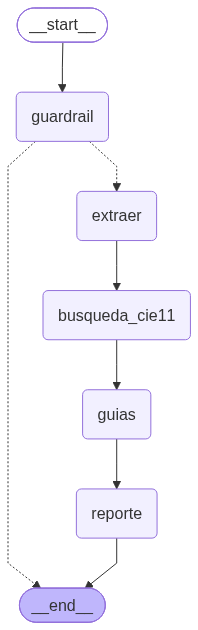

In [10]:
# 3.2 · Dibujo del workflow (no editar)
try:
    from IPython.display import Image, display
    display(Image(construir_workflow(componentes, {}).get_graph().draw_mermaid_png()))
except Exception:
    print(construir_workflow(componentes, {}).get_graph().draw_mermaid())

## 4 · Pruebas y evidencia (no editar)

In [11]:
# 4.1 · Ejecuta los casos y registra la evidencia (no editar)
import json
import time
import pandas as pd

def describir(r: dict) -> str:
    if r is None:
        return ""
    resumen = {
        "estado": r["estado_final"], "razon": r["razon"], "prob_clinico": r["prob_clinico"],
        "codigos": [c["codigo"] for c in r["candidatos"]], "rondas_busqueda_cie11": r["rondas_busqueda_cie11"], "guias": len(r["guias"]),
        "latencias_s": r["latencias"], "advertencias": r["advertencias"],
    }
    return json.dumps(resumen, ensure_ascii=False)

def rondas_de(observado: str):
    return json.loads(observado)["rondas_busqueda_cie11"] if observado else None

async def correr_casos(casos, componentes):
    filas = []
    for caso in casos:
        print(f"→ {caso['id']} · {caso['tipo']}")
        inicio = time.perf_counter()
        resultado, error = None, ""
        try:
            resultado = await ejecutar(caso["entrada"], componentes)
        except Exception as exc:
            error = f"{type(exc).__name__}: {exc}"
        latencia = round(time.perf_counter() - inicio, 2)
        try:
            paso = resultado is not None and bool(caso["verificar"](resultado))
        except Exception as exc:
            paso, error = False, error or f"Error al verificar: {exc}"
        filas.append({
            "template": TEMPLATE_ID, "id": caso["id"], "tipo": caso["tipo"], "entrada": caso["entrada"],
            "esperado": caso["esperado"], "criterio": caso["criterio"], "observado": describir(resultado),
            "veredicto_auto": "PASS" if paso else "FAIL", "veredicto_final": "",
            "latencia_s": latencia, "error": error,
        })
    return pd.DataFrame(filas)

registro = await correr_casos(CASOS, componentes)
pd.set_option("display.max_colwidth", 220)
vista = registro.assign(rondas=registro["observado"].map(rondas_de))
display(vista[["id", "tipo", "veredicto_auto", "rondas", "latencia_s", "observado", "error"]])
print(f"\nResultado automático: {(registro.veredicto_auto == 'PASS').sum()} de {len(registro)} casos en PASS")

→ P1 · caso completo
→ P2 · datos ausentes
→ P3 · fuera de contexto
→ P4 · instrucciones inyectadas


,id,tipo,veredicto_auto,rondas,latencia_s,observado,error
0,P1,caso completo,PASS,3,68.31,"{""estado"": ""ok"", ""razon"": """", ""prob_clinico"": 0.93, ""codigos"": [""6A70.1"", ""6A72"", ""6B43"", ""6A70.5""], ""rondas_busqueda_cie11"": 3, ""guias_apa"": 10, ""latencias_s"": {""anonimizar"": 2.122, ""guardrail"": 0.344, ""extraer"": 2....",
1,P2,datos ausentes,PASS,2,72.24,"{""estado"": ""ok"", ""razon"": """", ""prob_clinico"": 0.92, ""codigos"": [""6A70.Z"", ""6A70.1"", ""6A72"", ""7A00"", ""6E62.0"", ""MG22""], ""rondas_busqueda_cie11"": 2, ""guias_apa"": 10, ""latencias_s"": {""anonimizar"": 4.584, ""guardrail"": 0....",
2,P3,fuera de contexto,PASS,0,2.96,"{""estado"": ""fuera_de_alcance"", ""razon"": ""Probabilidad de contexto clínico 0.04 por debajo del umbral 0.5"", ""prob_clinico"": 0.04, ""codigos"": [], ""rondas_busqueda_cie11"": 0, ""guias_apa"": 0, ""latencias_s"": {""anonimizar""...",
3,P4,instrucciones inyectadas,PASS,0,0.56,"{""estado"": ""fuera_de_alcance"", ""razon"": ""Probabilidad de contexto clínico 0.05 por debajo del umbral 0.5"", ""prob_clinico"": 0.05, ""codigos"": [], ""rondas_busqueda_cie11"": 0, ""guias_apa"": 0, ""latencias_s"": {""anonimizar""...",



Resultado automático: 4 de 4 casos en PASS


In [12]:
# 4.2 · Guarda el registro de pruebas (no editar)
archivo = f"registro_pruebas_{TEMPLATE_ID}.csv"
registro.to_csv(archivo, index=False, encoding="utf-8-sig")
print("Registro guardado:", archivo)

Registro guardado: registro_pruebas_LC-B+C.csv


In [13]:
# 4.3 · Falla de conexión al MCP: el flujo debe detenerse sin reporte (no editar)
from poc_psico.agente import cargar_tools
from poc_psico.errores import FlujoDetenido

async def _agente_roto(sintomas):
    await cargar_tools("https://no-existe.invalid/sse", TOOLS_PERMITIDAS)

roto = Componentes(ner=ner_es, guardrail=_guardrail, extraer=crear_extractor(llm), busqueda_cie11=_agente_roto,
                   redactar=crear_redactor(llm), umbral=UMBRAL_GUARDRAIL)
r = await ejecutar(CASOS[0]["entrada"], roto)
assert r["estado_final"] == "error" and r["reporte_md"] == "", r
print("OK, se detuvo con:", r["razon"])

OK, se detuvo con: No se pudo conectar al MCP CIE-11 (https://no-existe.invalid/sse): unhandled errors in a TaskGroup (1 sub-exception)


## 5 · Prueba libre y reporte

In [14]:
# 5 · Prueba libre: escribe tu viñeta sintética
entrada = "Paciente de 41 años con ánimo irritable, preocupación constante y tensión muscular desde hace 8 meses."
r = await ejecutar(entrada, componentes)
print(r["estado_final"], "|", r["razon"])
from IPython.display import Markdown
Markdown(r["reporte_md"]) if r["reporte_md"] else None

ok | 


# Reporte de apoyo al psicodiagnóstico

## 1. Datos del caso

- Paciente: No identificado

- Edad: 41

- Sexo: No indicado

- Temporalidad: desde hace 8 meses

- Fecha del reporte: 2026-10-15

## 2. Síntomas por categoría

### Cognitivos

- Ninguno identificado

### Emocionales

- Ánimo irritable
- Preocupación constante

### Conductuales

- Tensión muscular

### Afectación social

- Ninguno identificado

## 3. Hipótesis diagnósticas (de la más a la menos plausible)

### 1. Trastorno de ansiedad generalizada — `6B00`

[Abrir en el navegador OMS](https://icd.who.int/browse/2026-01/mms/es#1712535455)

**Justificación:** El caso presenta preocupación constante, irritabilidad y tensión muscular de 8 meses de evolución, lo que coincide con el núcleo del trastorno de ansiedad generalizada (preocupación excesiva durante varios meses, con síntomas adicionales como tensión muscular e irritabilidad). Es la entidad más compatible entre los candidatos, aunque la evidencia es todavía parcial.

**Criterios cumplidos:**

- Preocupación constante de varios meses (8 meses)
- Irritabilidad
- Tensión muscular

**Criterios no cumplidos o sin confirmar:**

- Deterioro o angustia significativa en áreas funcionales: no documentado
- Número y tipo de preocupaciones (familia, salud, finanzas, trabajo): no especificado
- Dificultad de concentración y trastornos del sueño: no evaluados
- Exclusión de otra condición de salud, sustancias o medicamentos: no evaluada
- Duración con predominio de días con síntomas: no confirmada

### 2. Trastorno de adaptación — `6B43`

[Abrir en el navegador OMS](https://icd.who.int/browse/2026-01/mms/es#264310751)

**Justificación:** Si existiera un estresor psicosocial identificable que hubiera precedido el inicio de los síntomas hace 8 meses, la presentación de preocupación e irritabilidad podría corresponder a una reacción de adaptación. Se mantiene como alternativa porque el caso no documenta ningún estresor.

**Criterios cumplidos:**

- Preocupación por posibles consecuencias (si se confirmara un estresor)
- Duración compatible con seguimiento de 6 meses o más si el estresor persiste

**Criterios no cumplidos o sin confirmar:**

- Estresor psicosocial identificable: no consta
- Inicio dentro del mes posterior al estresor: no evaluado
- Deterioro significativo en la vida personal o laboral: no documentado
- Síntomas no explicables por otro trastorno mental: no evaluado; las exclusiones incluyen trastornos depresivos

### Ambigüedades

- No consta si existe un estresor que justifique 6B43 frente a 6B00
- Los síntomas son inespecíficos y podrían corresponder a otros cuadros
- La búsqueda en la fundación devolvió resultados vacíos
- La duración de dos años para 6A72 (trastorno distímico) la aportó el agente, no la herramienta; no se consultaron sus criterios
- 6A7Z (trastorno depresivo sin especificación) no fue evaluado; los síntomas del caso no son nucleares de depresión
- Las guías recuperadas (G1, G2) son de tratamiento farmacológico o de población mayor y no definen los criterios diagnósticos del caso; G3 no tiene contenido útil; G4 a G7 son de carácter general
- El sexo del paciente no consta y podría influir en la interpretación de los síntomas

## 4. Diferenciales y exclusiones

- Trastorno de adaptación (6B43) si se identifica un estresor
- Trastornos depresivos (6A7Z, 6A72, 6A70, 6A71) para descartar, dado que la irritabilidad puede ser síntoma depresivo
- Síndrome secundario del estado del ánimo con síntomas depresivos (6E62.0), a excluir por causa médica o sustancias
- Causas médicas (tiroideas, cardiológicas, endocrinas) que simulen ansiedad
- Consumo de sustancias, cafeína, estimulantes o medicamentos que produzcan ansiedad o irritabilidad
- Otros trastornos de ansiedad o trastorno obsesivo-compulsivo, no evaluados en el caso

### Alternativas consultadas y descartadas

- Trastornos depresivos, sin especificación (`6A7Z`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#1563440232%2Funspecified)

- Trastorno distímico (`6A72`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#810797047)

- Trastorno depresivo recurrente, sin especificación (`6A71.Z`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#1194756772%2Funspecified)

- Otro trastorno depresivo recurrente especificado (`6A71.Y`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#1194756772%2Fother)

- Trastorno depresivo, episodio único grave sin síntomas psicóticos (`6A70.3`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#1669279433)

- Síndrome secundario del estado del ánimo, con síntomas depresivos (`6E62.0`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#241382885)

- Otros trastornos depresivos especificados (`6A7Y`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#1563440232%2Fother)

- Trastorno depresivo de episodio único, sin especificación (`6A70.Z`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#578635574%2Funspecified)

- Otro trastorno depresivo de episodio único, especificado (`6A70.Y`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#578635574%2Fother)

- Trastorno depresivo recurrente, actualmente en remisión completa (`6A71.7`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#1763883082)

## 5. Datos faltantes por recabar

- Sexo del paciente
- Severidad de los síntomas
- Impacto funcional en trabajo, familia y relaciones
- Síntomas cognitivos: concentración y memoria
- Calidad del sueño
- Número y tipo de preocupaciones (familia, salud, finanzas, trabajo)
- Antecedentes médicos y psiquiátricos
- Medicamentos actuales
- Consumo de sustancias (alcohol, cafeína, estimulantes)
- Factores desencadenantes o eventos estresantes
- Presencia de estado de ánimo deprimido, anhedonia o pérdida de interés
- Frecuencia y duración de los días con síntomas en los últimos meses
- Síntomas autonómicos (palpitaciones, sudoración, molestias gastrointestinales)
- Edad confirmada: 41 años (dato recibido)

## 6. Pruebas complementarias sugeridas

> Sugerencias a validar por el profesional. Solo se indica el nombre de la prueba: no se incluyen cuestionarios ni formas de calificación.

- **Escala de Ansiedad de Hamilton**: Permite cuantificar la severidad de la ansiedad psíquica y somática para contrastar con la preocupación y tensión referidas. · _(sin referencia en las guías consultadas)_

- **Inventario de Ansiedad de Beck**: Ayuda a medir la intensidad de los síntomas ansiosos y a diferenciarlos de los depresivos. · _(sin referencia en las guías consultadas)_

- **Inventario de Depresión de Beck**: Permite descartar o confirmar un componente depresivo que podría explicar la irritabilidad. · _(sin referencia en las guías consultadas)_

- **Entrevista clínica estructurada para trastornos de ansiedad**: Facilita verificar criterios diagnósticos, duración, deterioro funcional y exclusiones de otras condiciones. · _(sin referencia en las guías consultadas)_

### Guías clínicas consultadas

> Referencias para consulta del profesional; el sistema no recomienda tratamientos.

**IMSS (México) · Guías de práctica clínica**

- [Diagnóstico y Tratamiento de los Trastornos de Ansiedad en el Adulto](https://www.imss.gob.mx/sites/all/statics/guiasclinicas/392GER.pdf) — «Deberá ser citado como: Guía de Práctica Clínica Diagnóstico y Tratamiento de los Trastornos de Ansi agnóstico y Tratamiento de los Trastornos de Ansiedad en el Adulto edad en el Adulto, México; ad en el Adulto Instituto Mexicano del Seguro Social, 2010. | | | Evidencia / Recomendación Evidencia / R»
- [DEL TRASTORNO DE ANSIEDAD GENERALIZADA EN LA PERSONA MAYOR](https://www.imss.gob.mx/sites/all/statics/guiasclinicas/499GER_0.pdf) — «Diagnóstico y tratamiento DEL TRASTORNO DE ANSIEDAD GENERALIZADA EN LA PERSONA MAYOR Evidencias y Recomendaciones Catálogo Maestro de Guías de Práctica Clínica GPC-IMSS-499-19 Actualización 2019 Debe ser citado como: Diagnóstico y Tratamiento del Trastorno de Ansiedad Generalizada en la Persona Mayo»
- [Guía de Referencia Rápida](https://www.imss.gob.mx/sites/all/statics/guiasclinicas/499GRR_0.pdf) — «| Error | | --- | | This page can't be displayed. Contact support for additional information.The incident ID is: N/A. | Error## Error ||**Error**| |This page can't be displayed. Contact support for additional information. The incident ID is: N/A.| |»

**APA · Evaluación, diagnóstico e intervención**

- [APA Guidelines for Psychological Assessment and Evaluation](https://www.apa.org/about/policy/guidelines-psychological-assessment-evaluation.pdf) — «ASSESSMENT The term assessment refers to a complex activity integrating knowl edge, clinical judgment, reliable collateral information (e.g., observa tion, semistructured or structured interviews, third-party report), and psychometric constructs with expertise in an area of professional practice or »
- [How psychologists help with anxiety disorders](https://www.apa.org/topics/anxiety/disorders) — «Psychologists are trained in diagnosing anxiety disorders and teaching patients healthier, more effective ways to cope. A form of psychotherapy known as cognitive-behavioral therapy (CBT) is highly effective at treating anxiety disorders. Through CBT, psychologists help patients learn to identify an»
- [Trastornos de la ansiedad: el papel de la psicoterapia en el tratamiento eficaz](https://www.apa.org/topics/anxiety/tratamiento) — «Por supuesto. La mayoría de los casos de trastornos de ansiedad pueden ser tratados satisfactoriamente por profesionales de la salud y la salud mental apropiadamente capacitados. Varias investigaciones han demostrado que tanto la terapia de conducta como la terapia cognitiva y de conducta (CBT) pued»
- [Más allá de la preocupación](https://www.apa.org/topics/anxiety/preocupacion) — «ansiedad. Las personas con este trastorno se preocupan por una amplia gama de cuestiones como problemas de salud o financieros, y pueden tener la sensación de que algo malo va a suceder. Entre los síntomas que presentan están: inquietud, irritabilidad,»

## 7. Aviso

Este reporte contiene hipótesis de apoyo generadas con ayuda de IA a partir de la CIE-11. No es un diagnóstico: la decisión clínica es del profesional.


In [15]:
# 5.1 · Prueba con foto de una nota manuscrita (Mistral OCR; la foto sale a OpenRouter y Mistral, usa solo fotos sintéticas; ver README)
RUTA_FOTO = "data/caso1_m_28.jpeg"  # EDITA AQUÍ: ruta a tu foto .jpg o .png; déjalo vacío para omitir
from IPython.display import Markdown

r = await ejecutar(RUTA_FOTO, componentes)
print("Texto leído (revísalo: un error de lectura cambia el sentido clínico):\n", r["texto_ocr"])
print(r["estado_final"], "|", r["razon"], "|", r["latencias"])
Markdown(r["reporte_md"]) if r["reporte_md"] else None

Texto leído (revísalo: un error de lectura cambia el sentido clínico):
 LUCTA 28 AÑOS

Vive con sus padres
Tiene 3 hermanos mayores

Refiere ansiedad al
estar en situaciones donde
hay mucha gente

Le cuesta trabajo hablam
con desconocidos. Refiere
que nosasiente escuchada en
casa y nunca ha creído
tener un lugar para poder
dar su opinión.

Terminó con su novio
hace 2 meses y desde eso
menos quiere salir de
casa e interactuar.
Hay días que tampoco
quiere levantarse en la
trabajo y que les fue
sólo duerme.
ok |  | {'ocr': 2.659, 'anonimizar': 2.748, 'guardrail': 0.403, 'extraer': 3.679, 'busqueda_cie11': 17.055, 'guias': 28.358, 'reporte': 12.166}


# Reporte de apoyo al psicodiagnóstico

## 1. Datos del caso

- Paciente: LU

- Edad: 28

- Sexo: No indicado

- Temporalidad: Terminó su relación de pareja hace 2 meses; el menor deseo de salir e interactuar comenzó desde entonces

- Fecha del reporte: 2026-10-15

## 2. Síntomas por categoría

### Cognitivos

- Ninguno identificado

### Emocionales

- Ansiedad en situaciones con mucha gente
- Sensación de no ser escuchada en casa
- No siente tener un lugar para dar su opinión

### Conductuales

- Dificultad para hablar con desconocidos
- Menor deseo de salir de casa e interactuar desde la ruptura
- Días en que no quiere levantarse de la cama
- Días en que solo duerme

### Afectación social

- Evita interactuar socialmente desde la ruptura de la relación de pareja
- Dificultad para hablar con desconocidos
- Vive con sus padres y tiene 3 hermanos mayores
- Afectación en el trabajo: días en que no quiere ir al trabajo

## 3. Hipótesis diagnósticas (de la más a la menos plausible)

### 1. Trastorno de adaptación — `6B43`

[Abrir en el navegador OMS](https://icd.who.int/browse/2026-01/mms/es#264310751)

**Justificación:** Los síntomas aparecen tras un estresante psicosocial identificable (ruptura de pareja hace 2 meses) y se acompañan de reacción desadaptativa: menor deseo de salir e interactuar, evitación social desde la ruptura, días en que no quiere levantarse ni ir al trabajo, y afectación laboral y familiar. Esto encaja con la preocupación por el factor estresante y la falta de adaptación con deterioro funcional. El inicio dentro del mes del estresante y la duración de hasta 6 meses son compatibles con el curso referido.

**Criterios cumplidos:**

- Estresante psicosocial identificable (ruptura de pareja hace 2 meses)
- Inicio de los síntomas tras el estresante (menor deseo de salir desde la ruptura)
- Evitación social desde la ruptura
- Deterioro en el trabajo (días sin ir al trabajo)
- Impacto en el funcionamiento familiar (sensación de no ser escuchada en casa)

**Criterios no cumplidos o sin confirmar:**

- Preocupación o cavilación sobre el factor estresante no documentada
- Ausencia de otro trastorno mental que lo explique mejor (no se ha evaluado estado de ánimo ni ansiedad previa)
- Grado de severidad del deterioro no cuantificado
- Duración y evolución no confirmadas

### 2. Trastorno de ansiedad social — `6B04`

[Abrir en el navegador OMS](https://icd.who.int/browse/2026-01/mms/es#2062286624)

**Justificación:** Hay ansiedad marcada en situaciones con mucha gente, dificultad para hablar con desconocidos y evitación social, lo que se ajusta al núcleo del trastorno de ansiedad social. Sin embargo, el criterio de síntomas persistentes durante al menos varios meses no se puede verificar: la evitación descrita data de hace 2 meses, por lo que el cuadro podría ser reciente y ligado a la ruptura.

**Criterios cumplidos:**

- Miedo o ansiedad marcados en situaciones sociales (multitudes)
- Dificultad para interactuar con desconocidos
- Evitación de situaciones sociales

**Criterios no cumplidos o sin confirmar:**

- Duración de al menos varios meses no confirmada (evitación de solo 2 meses)
- Inicio previo a la ruptura no documentado
- Preocupación por ser evaluada negativamente no explorada
- Deterioro atribuible a la ansiedad social no separado del efecto de la ruptura

### 3. Trastorno depresivo de episodio único, sin especificación — `6A70.Z`

[Abrir en el navegador OMS](https://icd.who.int/browse/2026-01/mms/es#578635574%2Funspecified)

**Justificación:** Se considera por el ánimo bajo de fondo sugerido por el menor deseo de salir, los días sin ganas de levantarse y los días en que solo duerme, tras una pérdida relevante. No se puede evaluar con criterios porque el agente no recuperó su definición; además, el trastorno de adaptación con síntomas depresivos debe descartarse como episodio único.

**Criterios cumplidos:**

- Posible disminución del interés y de la actividad (menor deseo de salir e interactuar)
- Alteración del sueño y de la energía (días sin levantarse, días de solo dormir)

**Criterios no cumplidos o sin confirmar:**

- Estado de ánimo deprimido no documentado
- Anhedonia no explorada
- Duración mínima de 2 semanas no confirmada en la descripción
- Número de síntomas y criterios CIE-11 no evaluados por falta de definición disponible

### Ambigüedades

- El agente no pudo evaluar 6A70.Z porque la herramienta no devolvió definición ni criterios
- La relación temporal entre la ansiedad social y la ruptura no está clara
- No se sabe si la ansiedad en multitudes existía antes de la ruptura
- Los días de hipersomnia y la falta de ganas de levantarse podrían ser síntomas depresivos o reacción al estrés
- Puede haber coexistencia de trastorno de adaptación y ansiedad social, o diferenciación según la historia previa
- El término 'no ser escuchada' en casa puede reflejar conflicto familiar o problemas de autoestima

## 4. Diferenciales y exclusiones

- Trastorno depresivo de episodio único (6A70.Z; descartar por criterios de ánimo, anhedonia y duración)
- Trastorno depresivo de episodio único, leve/moderado/grave (6A70.0, 6A70.1, 6A70.3) como alternativas descartadas a revisar
- Episodio depresivo persistente (6A80.2) o con melancolía (6A80.3) si el ánimo bajo se prolonga
- Trastorno depresivo recurrente (6A71.Z) si hay episodios previos
- Duelo sin complicaciones o trastorno por duelo prolongado, por la pérdida de la relación
- Mutismo selectivo (6B06), descartado porque la dificultad es solo para hablar con desconocidos, no mutismo generalizado
- Trastornos específicamente asociados con el estrés, sin especificación (6B4Z), por si los criterios de adaptación no se cumplen
- Trastorno de ansiedad social (6B04) como diagnóstico principal o comórbido si hay historia previa
- Consumo de sustancias como causa de cambios en el sueño y la ansiedad, no evaluado
- Trastornos asociados al embarazo o puerperio (6E20/6B43), descartado por no haber indicios; sexo no documentado

### Alternativas consultadas y descartadas

- Trastornos específicamente asociados con el estrés, sin especificación (`6B4Z`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#991786158%2Funspecified)

- Mutismo selectivo (`6B06`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#167946871)

- Trastornos mentales o del comportamiento asociados con el embarazo, el parto o el puerperio, sin síntomas psicóticos [Trastorno de adaptación] (`6E20/6B43`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#264310751)

- Trastorno depresivo de episodio único, moderado, sin síntomas psicóticos (`6A70.1`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#399670840)

- Otro trastorno depresivo de episodio único, especificado (`6A70.Y`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#578635574%2Fother)

- Trastorno depresivo recurrente, sin especificación (`6A71.Z`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#1194756772%2Funspecified)

- Episodio depresivo actual persistente (`6A80.2`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#1906190365)

- Episodio depresivo actual con melancolía (`6A80.3`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#802537726)

- Trastorno depresivo, episodio único grave sin síntomas psicóticos (`6A70.3`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#1669279433)

- Trastorno depresivo de episodio único, leve (`6A70.0`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#1922675618)

## 5. Datos faltantes por recabar

- Sexo del paciente
- Edad exacta de inicio de la ansiedad en multitudes
- Duración de la ansiedad en situaciones con mucha gente antes de la ruptura
- Severidad de la ansiedad y de los síntomas
- Frecuencia de los días sin ganas de levantarse y de los días de solo dormir
- Impacto en el trabajo y en la vida familiar
- Estado de ánimo, tristeza, anhedonia, culpa o desesperanza
- Ideación suicida o autolesiva
- Alteraciones del apetito, peso y sueño fuera de los días de hipersomnia
- Consumo de sustancias
- Antecedentes psiquiátricos personales y familiares
- Antecedentes de ansiedad social previos
- Preocupación o cavilación sobre la ruptura
- Dinámica familiar y calidad de las relaciones
- Funcionamiento en el trabajo y en casa
- Episodios depresivos previos
- Comorbilidades médicas

## 6. Pruebas complementarias sugeridas

> Sugerencias a validar por el profesional. Solo se indica el nombre de la prueba: no se incluyen cuestionarios ni formas de calificación.

- **Entrevista clínica estructurada para trastornos del estado de ánimo y ansiedad**: Permite confirmar o descartar los criterios de episodio depresivo y de ansiedad social con un método estandarizado. · Referencia: [APA Guidelines on Evidence-Based Psychological Practice in Health Care](https://www.apa.org/about/policy/psychological-practice-health-care.pdf) — «Structured clinical interviews and adherence to diagnostic criteria are associated with»

- **Inventario de Ansiedad Social de Liebowitz**: Cuantifica la ansiedad y la evitación en situaciones sociales para determinar su severidad y su relación temporal con la ruptura. · _(sin referencia en las guías consultadas)_

- **Inventario de Depresión de Beck**: Evalúa la severidad de los síntomas depresivos, incluyendo ánimo, anhedonia y desesperanza, para diferenciar del trastorno de adaptación. · _(sin referencia en las guías consultadas)_

- **Escala de Evaluación de Estrés Percibido**: Mide el grado de estrés percibido asociado a la ruptura y al entorno familiar para valorar la relación con el estresante. · _(sin referencia en las guías consultadas)_

### Guías clínicas consultadas

> Referencias para consulta del profesional; el sistema no recomienda tratamientos.

**IMSS (México) · Guías de práctica clínica**

- [Diagnóstico y Tratamiento de los Trastornos de Ansiedad en el Adulto](https://www.imss.gob.mx/sites/all/statics/guiasclinicas/392GER.pdf) — «Diagnóstico y Tratamiento de los Trastornos de Ansiedad en el Adulto Evidencias y Recomendaciones Catálogo Maestro de Guías de Práctica Clínica: IMSS-392-10 Deberá ser citado como: Guía de Práctica Clínica Diagnóstico y Tratamiento de los Trastornos de Ansi agnóstico y Tratamiento de los Trastornos »
- [GUÍA DE PRÁCTICA CLÍNICAGPC](https://www.imss.gob.mx/sites/all/statics/guiasclinicas/161GER.pdf) — «GUÍA DE PRÁCTICA CLÍNICAGPC diagnóstico y tratamiento DEL TRASTORNO DEPRESIVO en el adulto Evidencias y Recomendaciones Catálogo Maestro de Guías de Práctica Clínica: IMSS-161-09 CIE- 10: F 32 EPISODIO DEPRESIVO F33 TRASTORNO DEPRESIVO RECURRENTE GPC: DIAGNÓSTICO Y TRATAMIENTO DEL TRASTORNO DEPRESIV»
- [Guías de práctica clínica](https://imss.gob.mx/guias_practicaclinica?field_categoria_gs_value=30) — «- GRR : Guía de Referencia Rápida - GER : Guía de Evidencias y Recomendaciones (guía completa) IMSS-161-09, Diagnóstico y Tratamiento del Trastorno Depresivo en el Adulto IMSS-392-10, Trastorno Ansiedad en el Adulto GER Ansiedad»

**APA · Evaluación, diagnóstico e intervención**

- [APA Guidelines for Psychological Assessment and Evaluation](https://www.apa.org/about/policy/guidelines-psychological-assessment-evaluation.pdf) — «ASSESSMENT The term assessment refers to a complex activity integrating knowl edge, clinical judgment, reliable collateral information (e.g., observa tion, semistructured or structured interviews, third-party report), and psychometric constructs with expertise in an area of professional practice or »
- [How psychologists help with anxiety disorders](https://www.apa.org/topics/anxiety/disorders) — «In some cases, medications have a role in treating anxiety disorders. Yet research shows behavioral treatment, alone or in combination with medication, is a highly effective treatment for most people with an anxiety disorder. Psychologists are trained in diagnosing anxiety disorders and teaching pat»
- [APA Guidelines on Evidence-Based Psychological Practice in Health Care](https://www.apa.org/about/policy/psychological-practice-health-care.pdf) — «Psychologists endeavor to conduct assessments that are appropriate for the setting, purpose, and population. Rationale The overarching purposes of psychological assessment are to clarify patients’ present ing concerns, gather information that con tributes to case conceptualization and informs treatm»
- [Depression Treatments for Adults](https://www.apa.org/depression-guideline/adults) — «Treatment begins with a comprehensive evaluation of the person’s social and emotional functioning along with educating the patient about the biopsychosocial model of depression, emphasizing that the illness does not define the person. Next, the therapist will ask questions about their relationships »

**OMS**

- [Guía de intervención mhGAP para los trastornos mentales, neurológicos y por uso de sustancias en el nivel de atención de la salud no especializada](https://www.who.int/es/publications/i/item/978924154806) — «de intervencio mhGAP para los trastornos mentales, neurológicos y por uso de sustancias en el nivel de atencio de la salud no especializada de intervención mhGAP para los trastornos mentales, neurolo gicos y»
- [mhGAP Intervention guide for mental, neurological and substance-use disorders in non-specialized health settings. Version 2.0](https://www.who.int/publications/b/31377) — «The mhGAP Intervention Guide (mhGAP-IG) for mental, neurological and substance use disorders for non-specialist health settings, is a technical tool developed by WHO to assist in implementation of mhGAP. The Intervention Guide has been developed through a systematic review of evidence followed by an»
- [Directriz del Programa de Acción para Superar las Brechas en Salud Mental (mhGAP) para los trastornos mentales, neurológicos y por consumo de sustancias](https://iris.who.int/server/api/core/bitstreams/6373dd11-15bb-478d-a66b-6c07f70d84b3/content) — «Los trastornos mentales, neurológicos y por consumo de sustancias son los principales factores que contribuyen a la morbilidad y la mortalidad prematura en todas las regiones del mundo. Los recursos que se han proporcionado para hacer frente a la enorme carga de dichos trastornos son insuficientes, »

## 7. Aviso

Este reporte contiene hipótesis de apoyo generadas con ayuda de IA a partir de la CIE-11. No es un diagnóstico: la decisión clínica es del profesional.


## 6 · Cierre del PoC
Completa esta celda antes de entregar (doble clic para editar).

- **Hipótesis evaluada:**
- **Resultado:** _ de 4 casos en PASS, con veredicto revisado.
- **Evidencia principal:** (rondas del agente, latencias, códigos obtenidos)
- **Guardrail:** Decisions API o plan B con LLM, y por qué.
- **Limitación principal:**
- **Decisión:** continuar / ajustar / descartar.